In [1]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 19

neuron_labels = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
				 'RMDDR', 'SMDDR', 'SMDDL',					# C
				 'AVAR', 'AVAL',							# M
				 'ALA', 'AWBR']								# O
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 2
dims_preca = 5

In [4]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymograph) = read_utils.get_data(path, file_id)
timestamps = read_utils.get_timestamps(read_utils.get_file_handle(path, file_id))

# clear nan values
mask = eigenworms.notna().all(axis=1)

traces = traces[mask]
continuous_behaviors = continuous_behaviors[mask]
eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]
kymograph = kymograph[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
pass

In [5]:
neuron_labels = [label for label in neuron_labels if label in traces.columns]

In [6]:
# reduce

(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca([traces],
																	[discrete_states[bhl_selection]],
																	scale=(False, False),
																	n_cv=dims, n_pc=dims_preca)

modes = modes_manifold[0]
traces_reconstructed = recos_manifold[0]
traces_residual = pd.DataFrame(traces.values - traces_reconstructed.values, columns=traces.columns)

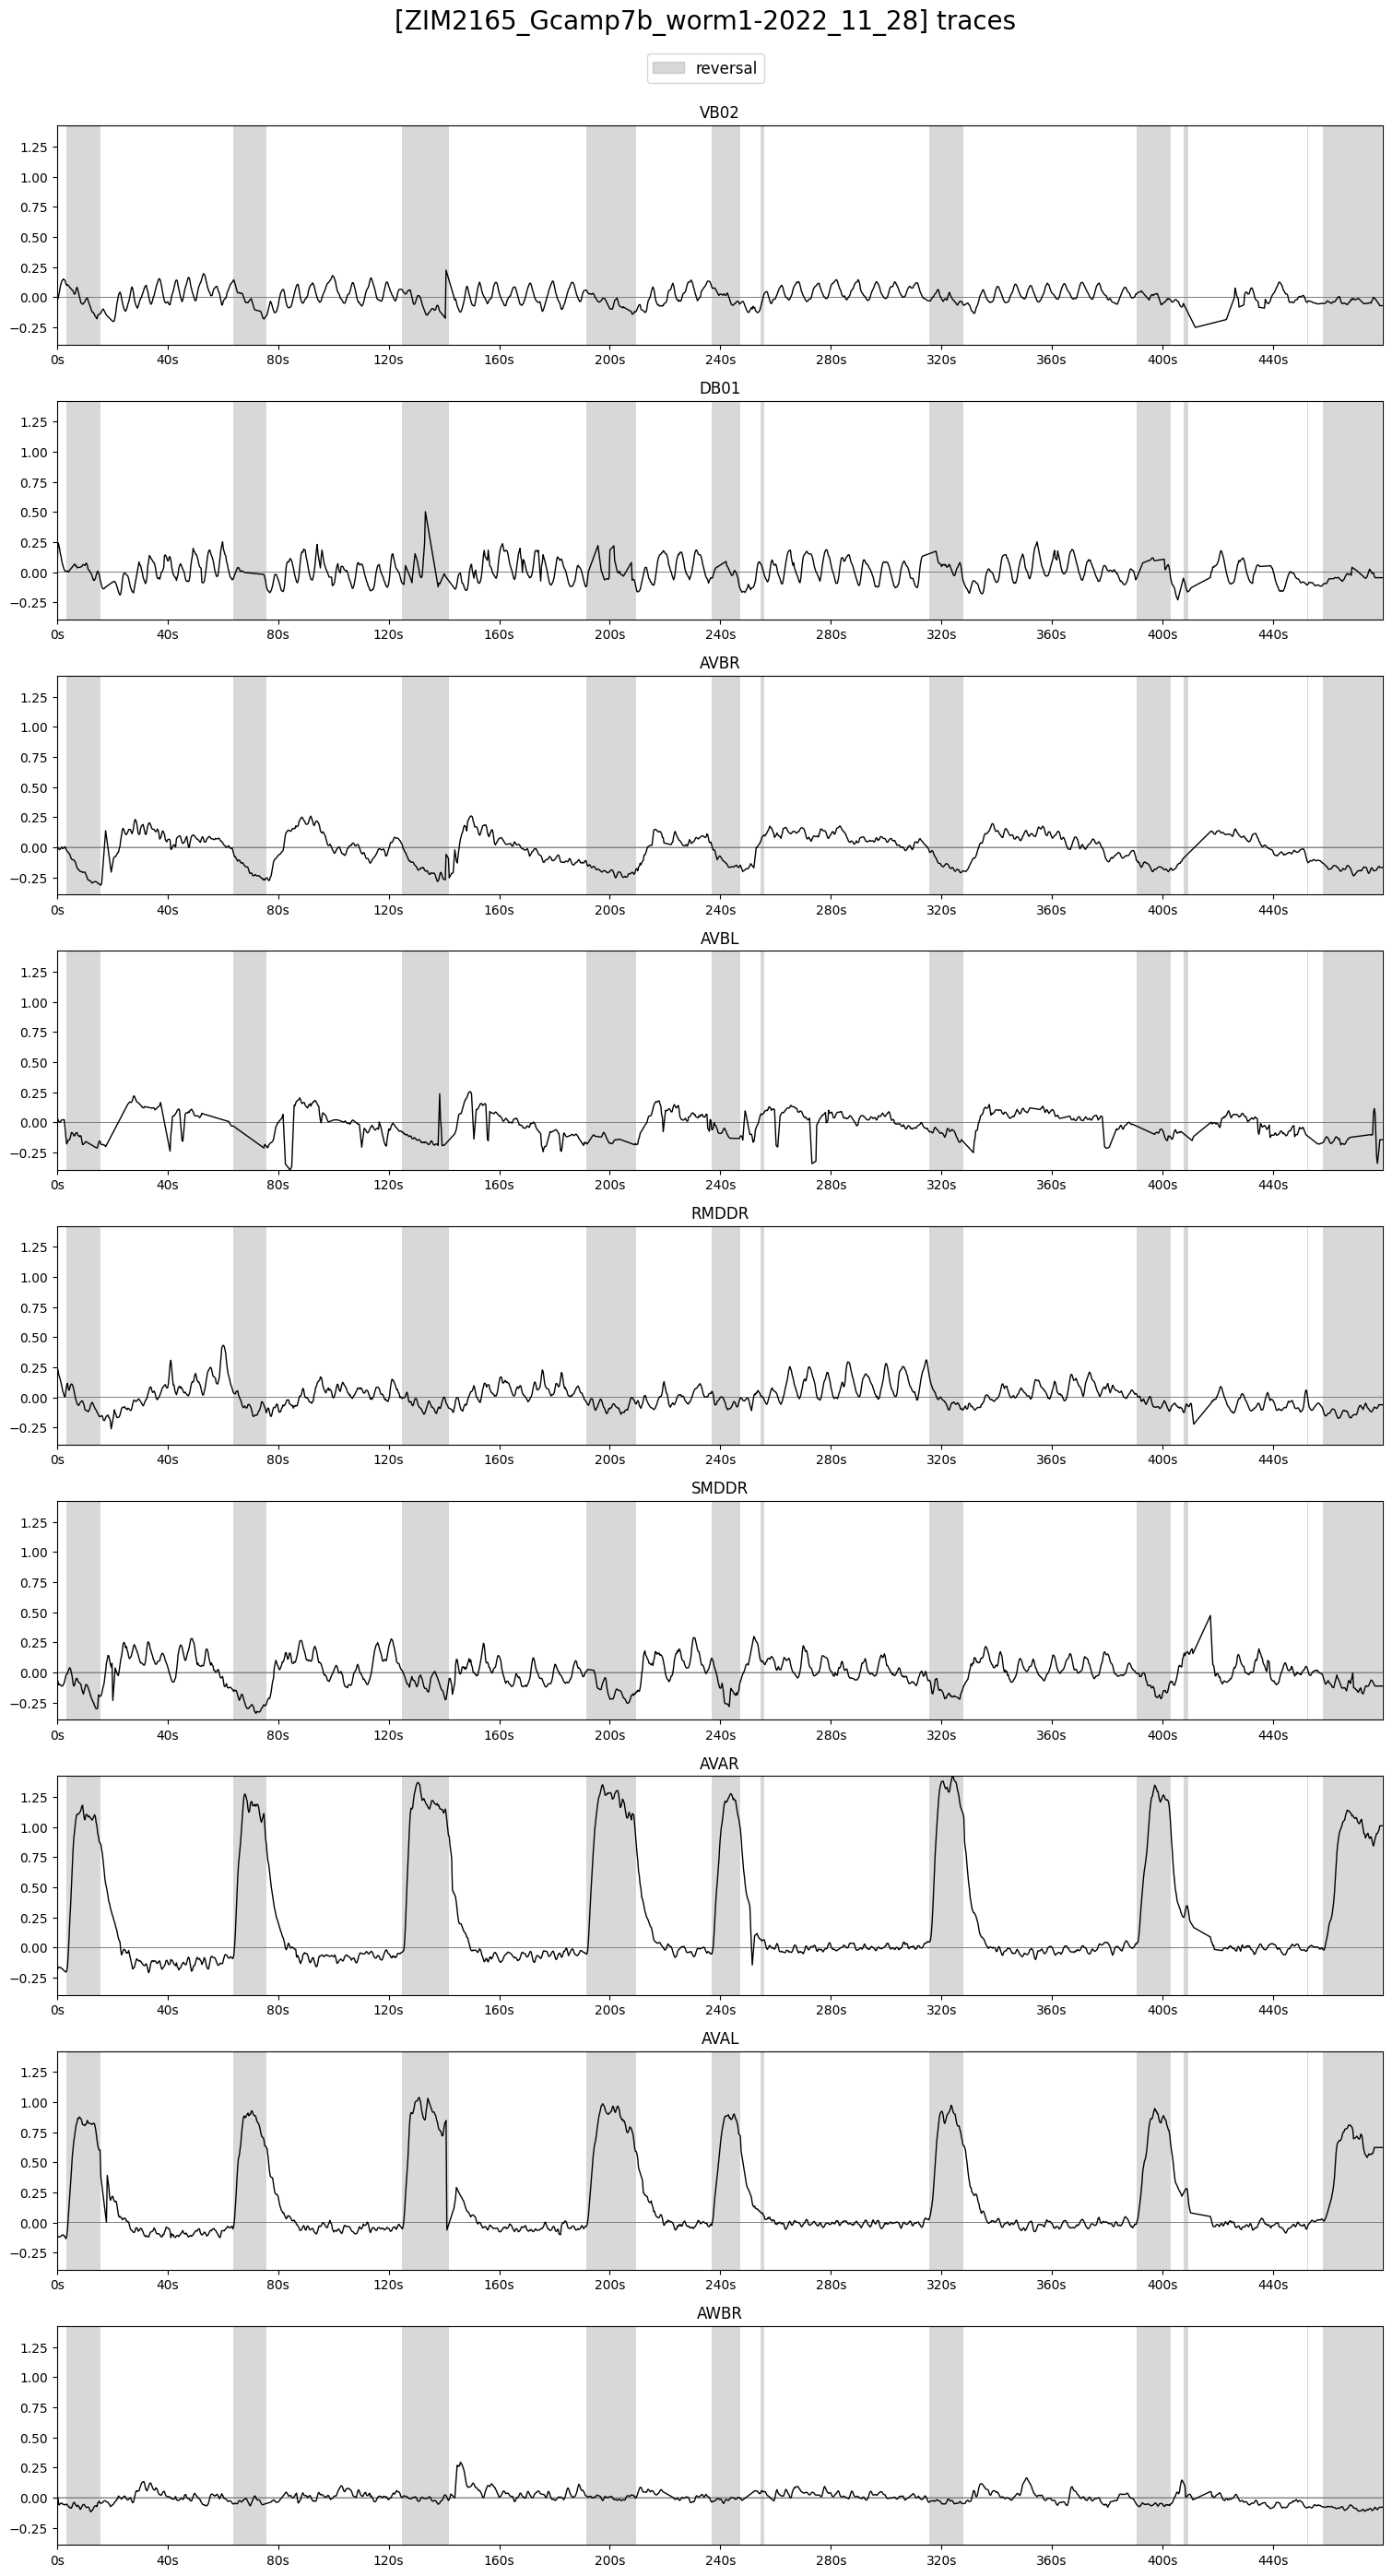

In [8]:
importlib.reload(plot_utils)
plot_utils.plot_traces(traces[neuron_labels],
					   discrete_states[['REV']],
					   timestamps,
					   label='reversal',
					   title=f'[{filename}] traces', ylimits=None, plots_per_row=1)

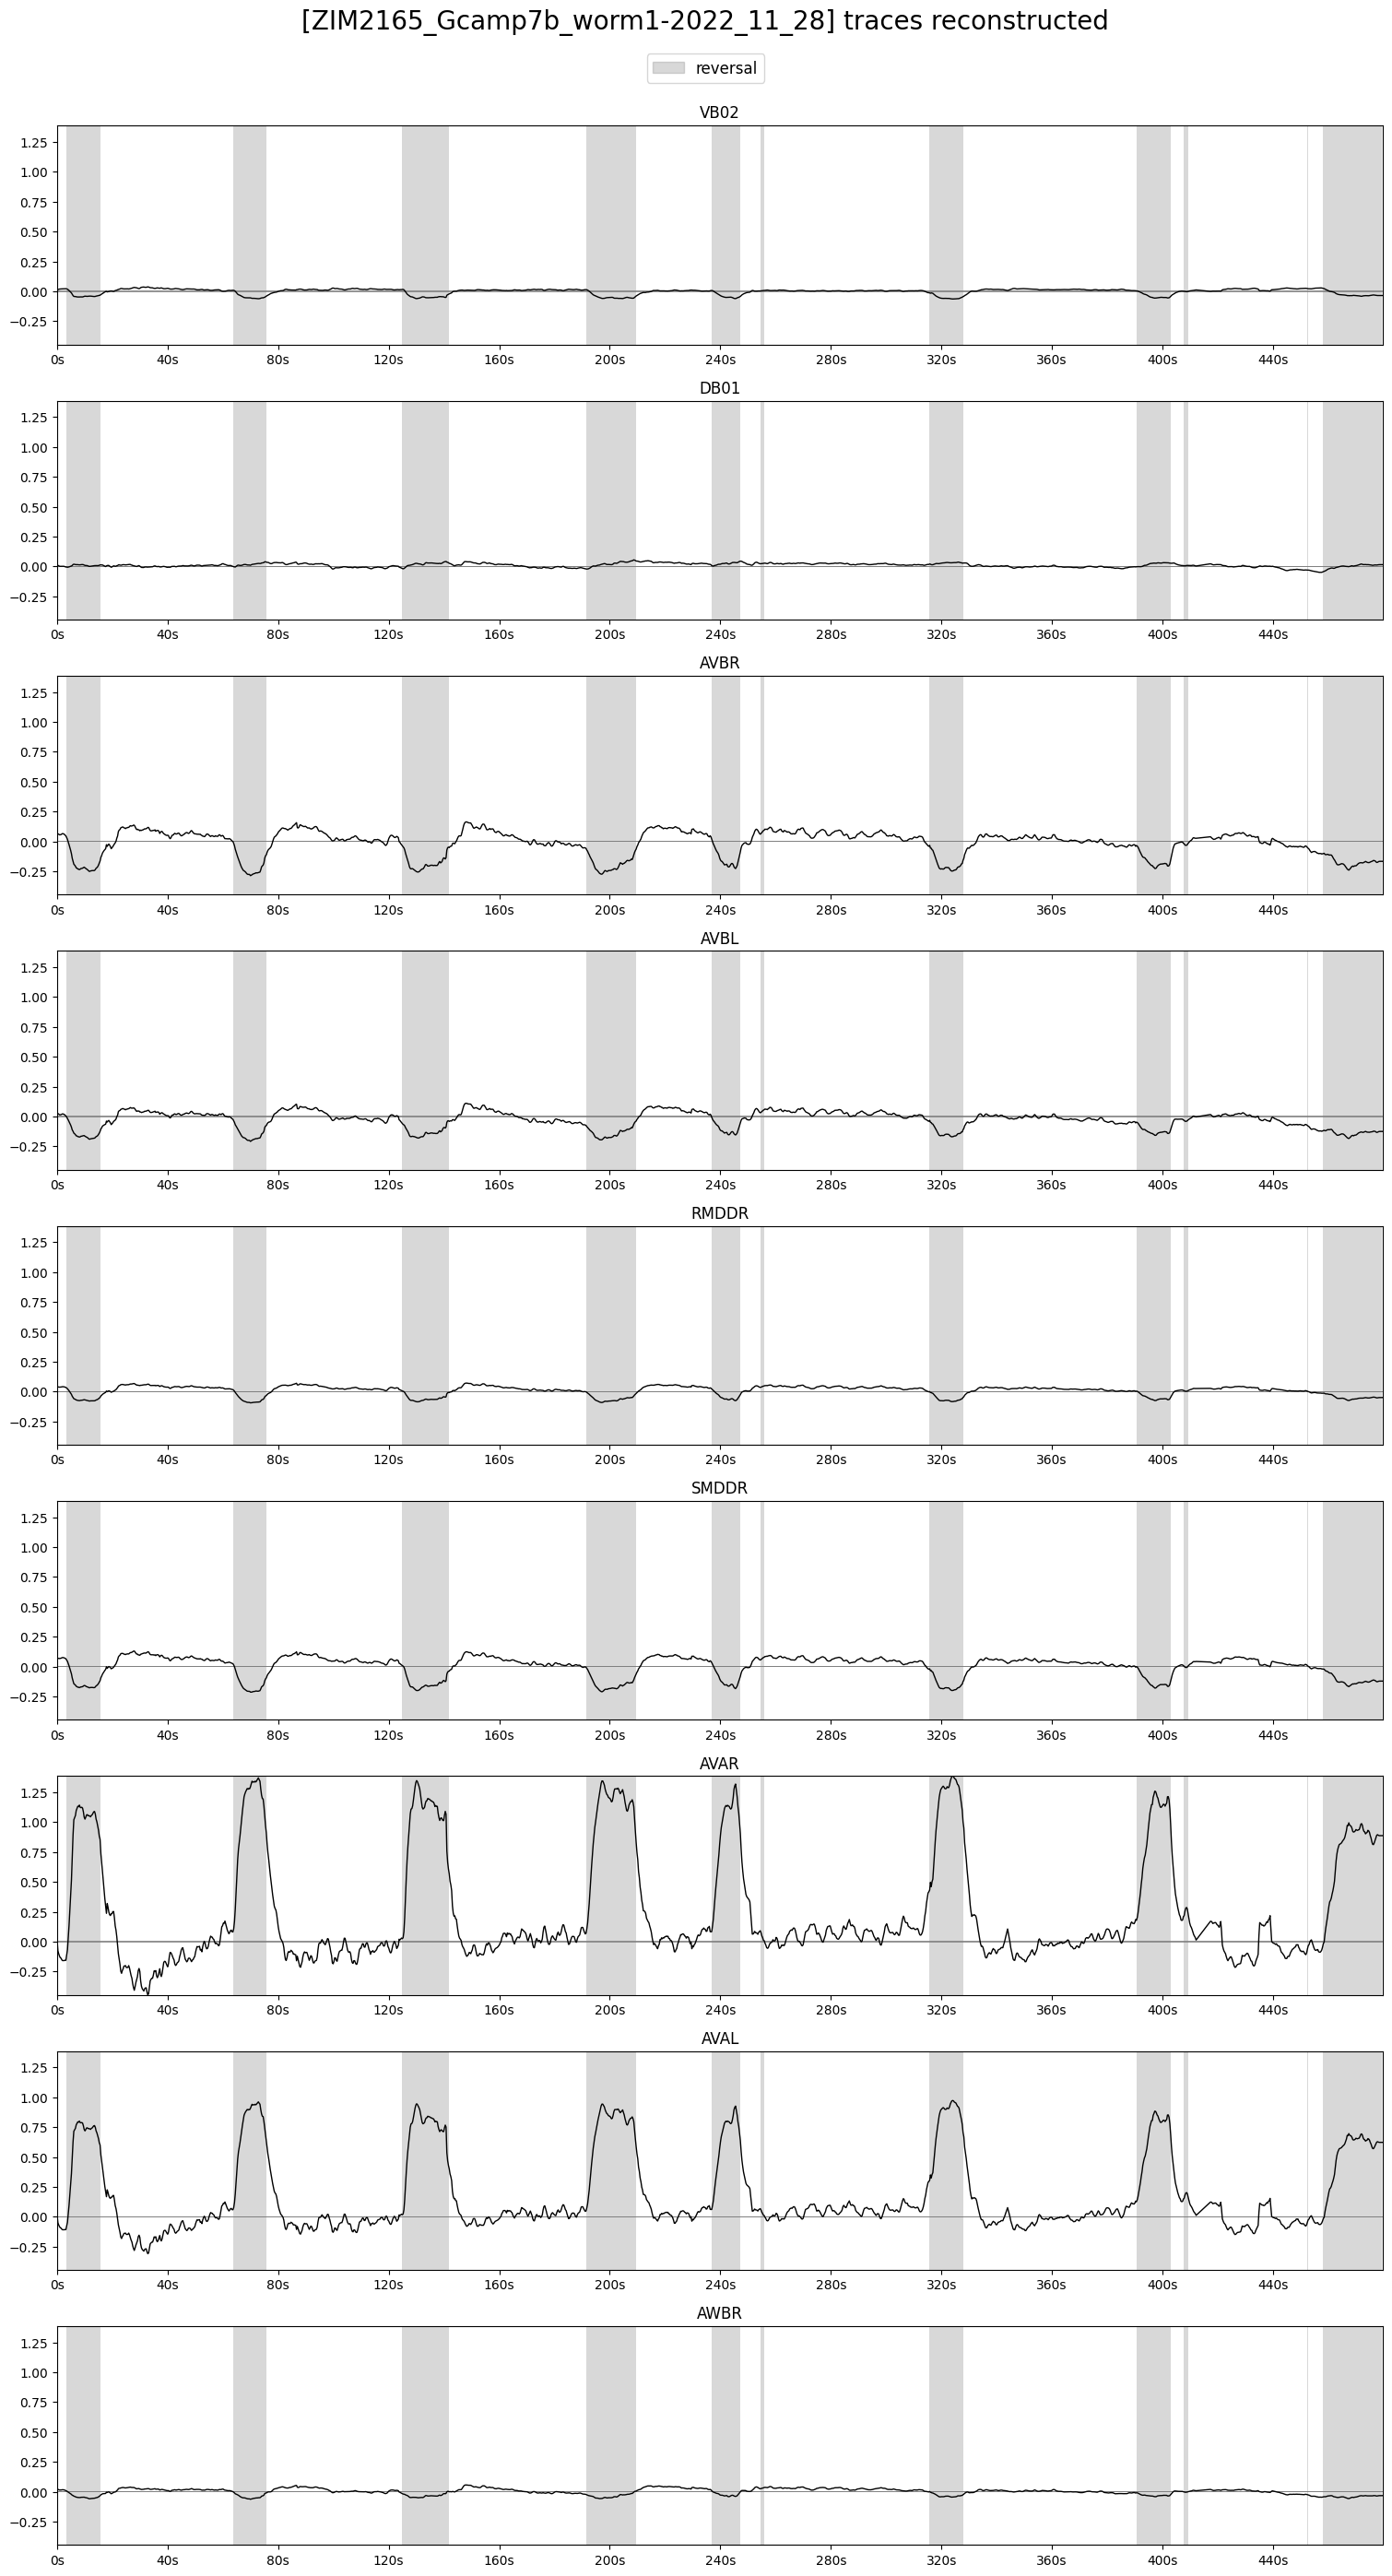

In [9]:
plot_utils.plot_traces(traces_reconstructed[neuron_labels],
					   discrete_states[['REV']],
					   timestamps,
					   ylimits=None, label='reversal',
					   title=f'[{filename}] traces reconstructed',
					   plots_per_row=1)

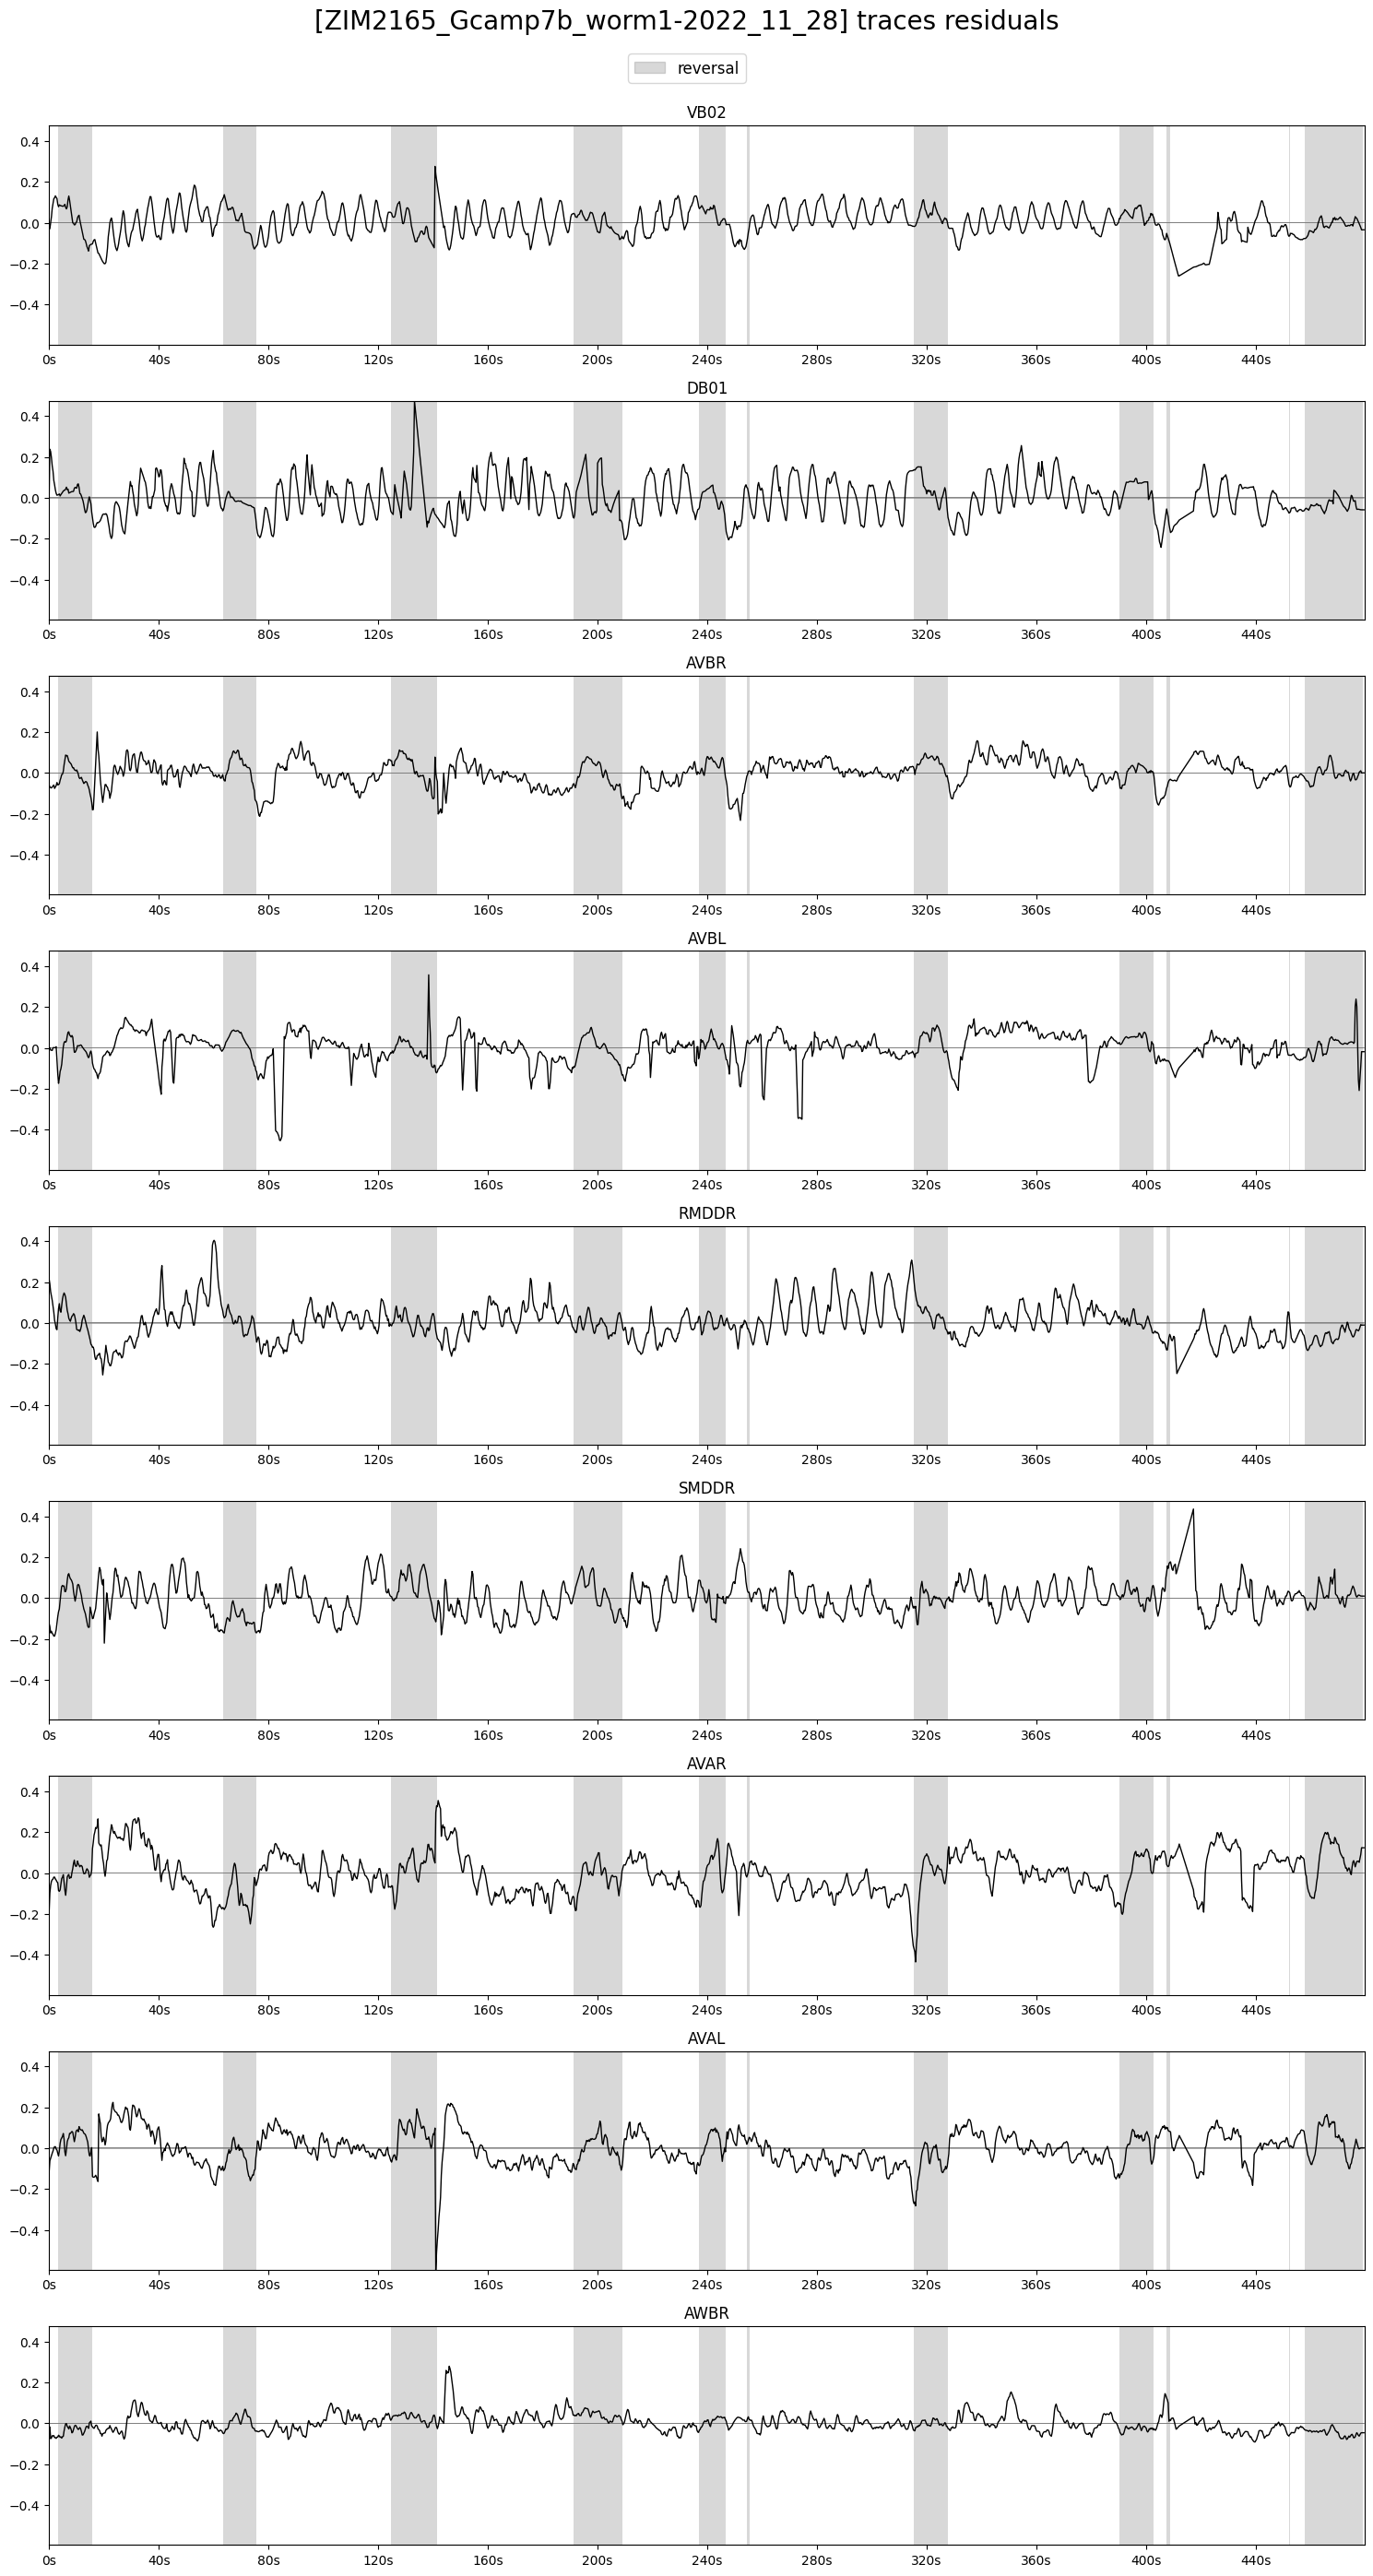

In [10]:
plot_utils.plot_traces(traces_residual[neuron_labels],
					   discrete_states[['REV']],
					   timestamps,
					   ylimits=None, label='reversal',
					   title=f'[{filename}] traces residuals',
					   plots_per_row=1)

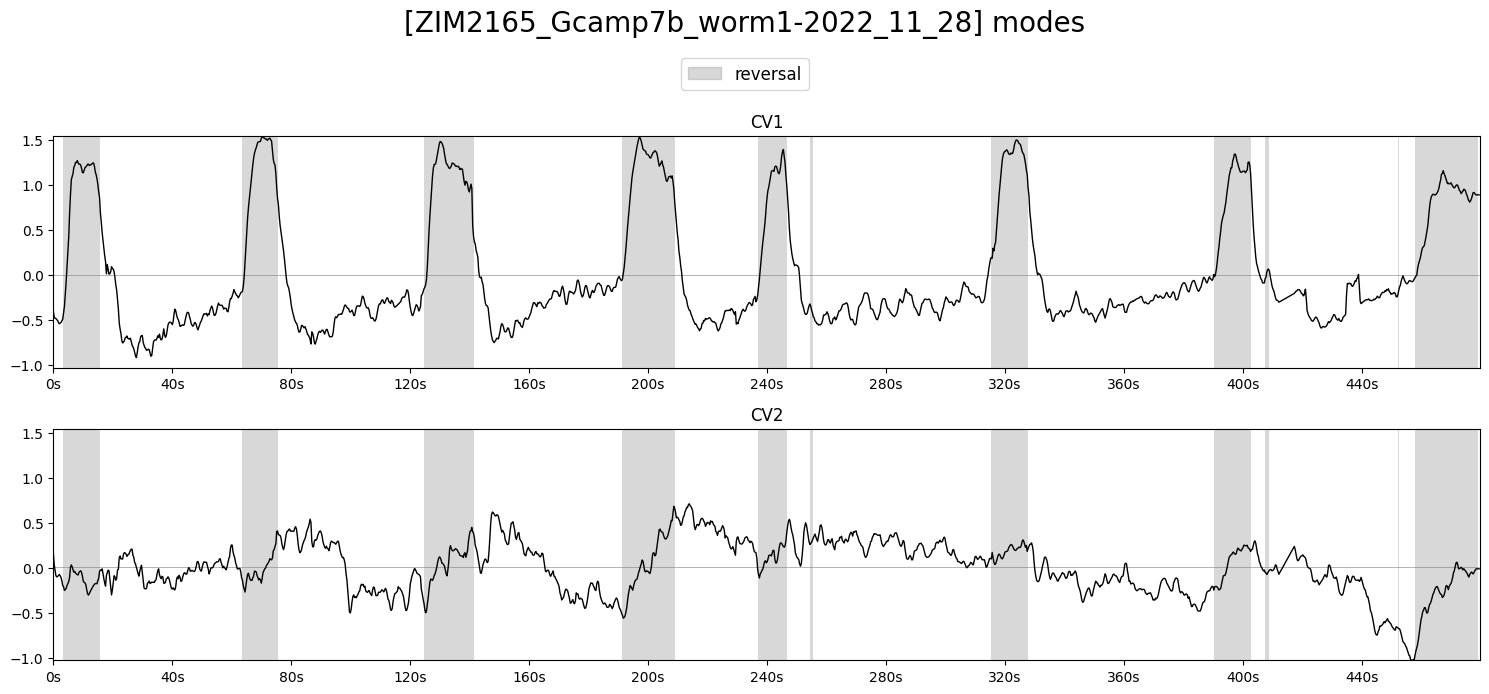

In [11]:
plot_utils.plot_traces(modes,
					   discrete_states[['REV']],
					   timestamps,
					   label='reversal',
					   title=f'[{filename}] modes', ylimits=None, plots_per_row=1)

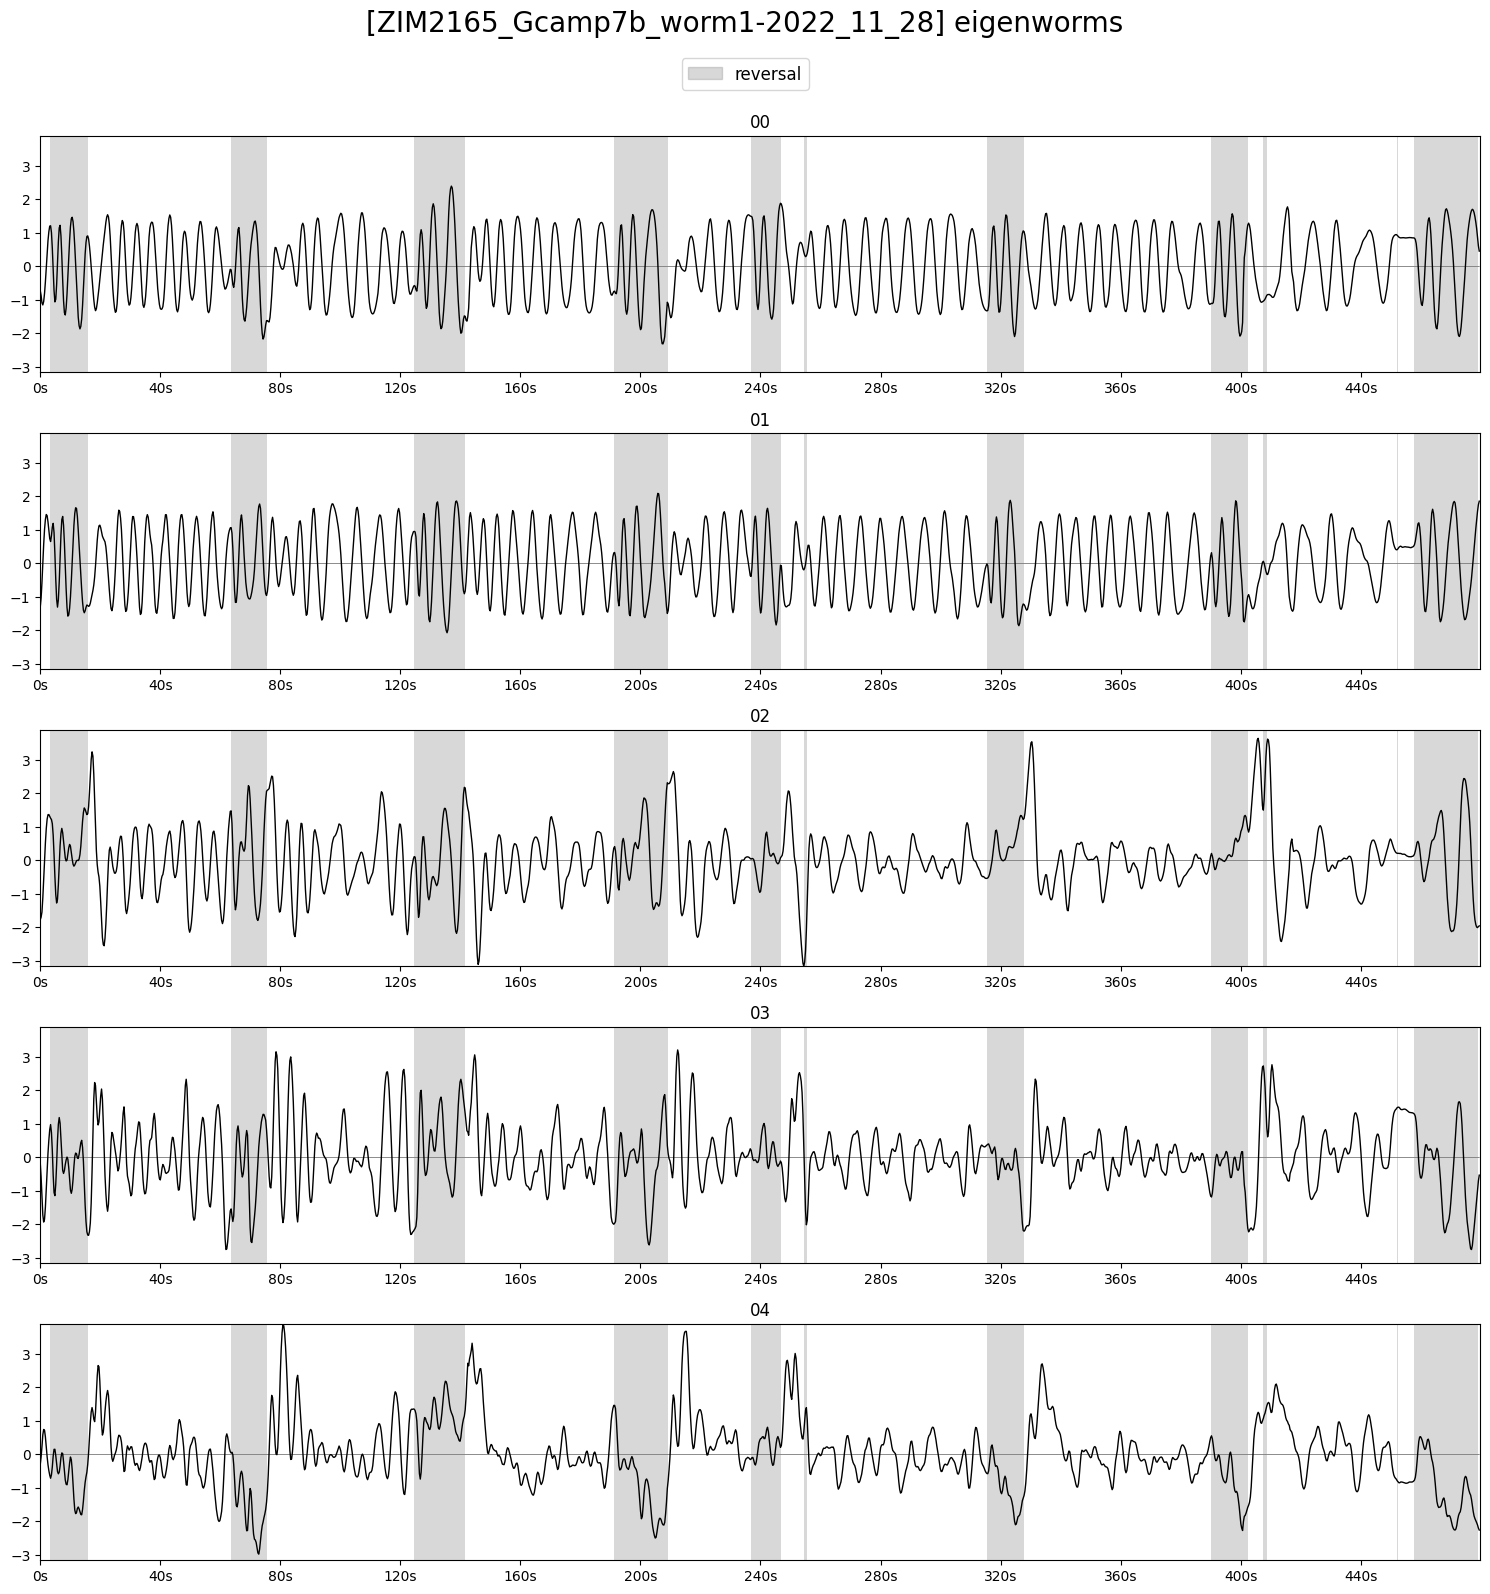

In [12]:
plot_utils.plot_traces(eigenworms,
					   discrete_states[['REV']],
					   timestamps,
					   label='reversal',
					   title=f'[{filename}] eigenworms', ylimits=None, plots_per_row=1)